In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Se realiza la carga de los datos.

In [10]:
train = pd.read_csv("./train.csv")
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Dimensiones y tipos de datos (train.csv)

In [11]:
print(f'Filas: {train.shape[0]}, Columnas: {train.shape[1]}')
train.dtypes

Filas: 1460, Columnas: 81


Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object

In [12]:
test = pd.read_csv('./test.csv')
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


Dimensiones y tipos de datos (test.csv)

In [13]:
print(f'Filas: {test.shape[0]}, Columnas: {test.shape[1]}')
train.dtypes

Filas: 1459, Columnas: 80


Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object

Valores faltantes (train.csv)

In [14]:
valores_faltantes = train.isnull().sum().to_frame(name='Valores_Faltantes')
valores_faltantes['% Faltante'] = (valores_faltantes['Valores_Faltantes'] / len(train) * 100).round(2)
valores_faltantes

,Valores_Faltantes,% Faltante
Id,0,0.00
MSSubClass,0,0.00
MSZoning,0,0.00
LotFrontage,259,17.74
LotArea,0,0.00
...,...,...
MoSold,0,0.00
YrSold,0,0.00
SaleType,0,0.00
SaleCondition,0,0.00


In [15]:
numeric_df = train.select_dtypes(include=[np.number])
corr = numeric_df.corr()['SalePrice'].sort_values(ascending=False)
top_20_features = corr.index[1:21].tolist()

print(f"Las 20 variables seleccionadas son:\n{top_20_features}\n")

Las 20 variables seleccionadas son:
['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'Fireplaces', 'BsmtFinSF1', 'LotFrontage', 'WoodDeckSF', '2ndFlrSF', 'OpenPorchSF', 'HalfBath', 'LotArea']



Estrategia de Imputación de Valores Faltantes
Para garantizar la calidad de los datos antes del modelado, aplicamos técnicas de imputación específicas basadas en el diccionario de datos (data_description.txt):

LotFrontage: Se imputa utilizando la mediana agrupada por vecindario (Neighborhood). Las propiedades en una misma zona comparten características geoespaciales y normativas, lo que hace que la estimación local sea mucho más precisa que una mediana global.

GarageYrBlt: Los valores nulos corresponden a propiedades que no poseen garaje. Al imputarlos con 0, creamos una separación matemática clara que los algoritmos podrán aislar fácilmente, distinguiéndolas de las casas construidas en años reales.

MasVnrArea: Los nulos representan la ausencia de revestimiento de mampostería exterior. Por definición física, el área correspondiente es 0.

Imputación de Seguridad: Cualquier nulo residual en el set de prueba para las 20 variables principales se rellena con la mediana global para evitar interrupciones durante el entrenamiento de los algoritmos predictivos.

In [16]:
train['LotFrontage'] = train.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
test['LotFrontage'] = test.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

train['GarageYrBlt'] = train['GarageYrBlt'].fillna(0)
test['GarageYrBlt'] = test['GarageYrBlt'].fillna(0)

train['MasVnrArea'] = train['MasVnrArea'].fillna(0)
test['MasVnrArea'] = test['MasVnrArea'].fillna(0)

for col in top_20_features:
    if train[col].isnull().any():
        train[col] = train[col].fillna(train[col].median())
    if test[col].isnull().any():
        test[col] = test[col].fillna(test[col].median())

train.to_csv('train_limpio.csv', index=False)
test.to_csv('test_limpio.csv', index=False)

print("Imputación finalizada. Archivos 'train_limpio.csv' y 'test_limpio.csv' generados.")

Imputación finalizada. Archivos 'train_limpio.csv' y 'test_limpio.csv' generados.


## Distribución de las variables numéricas

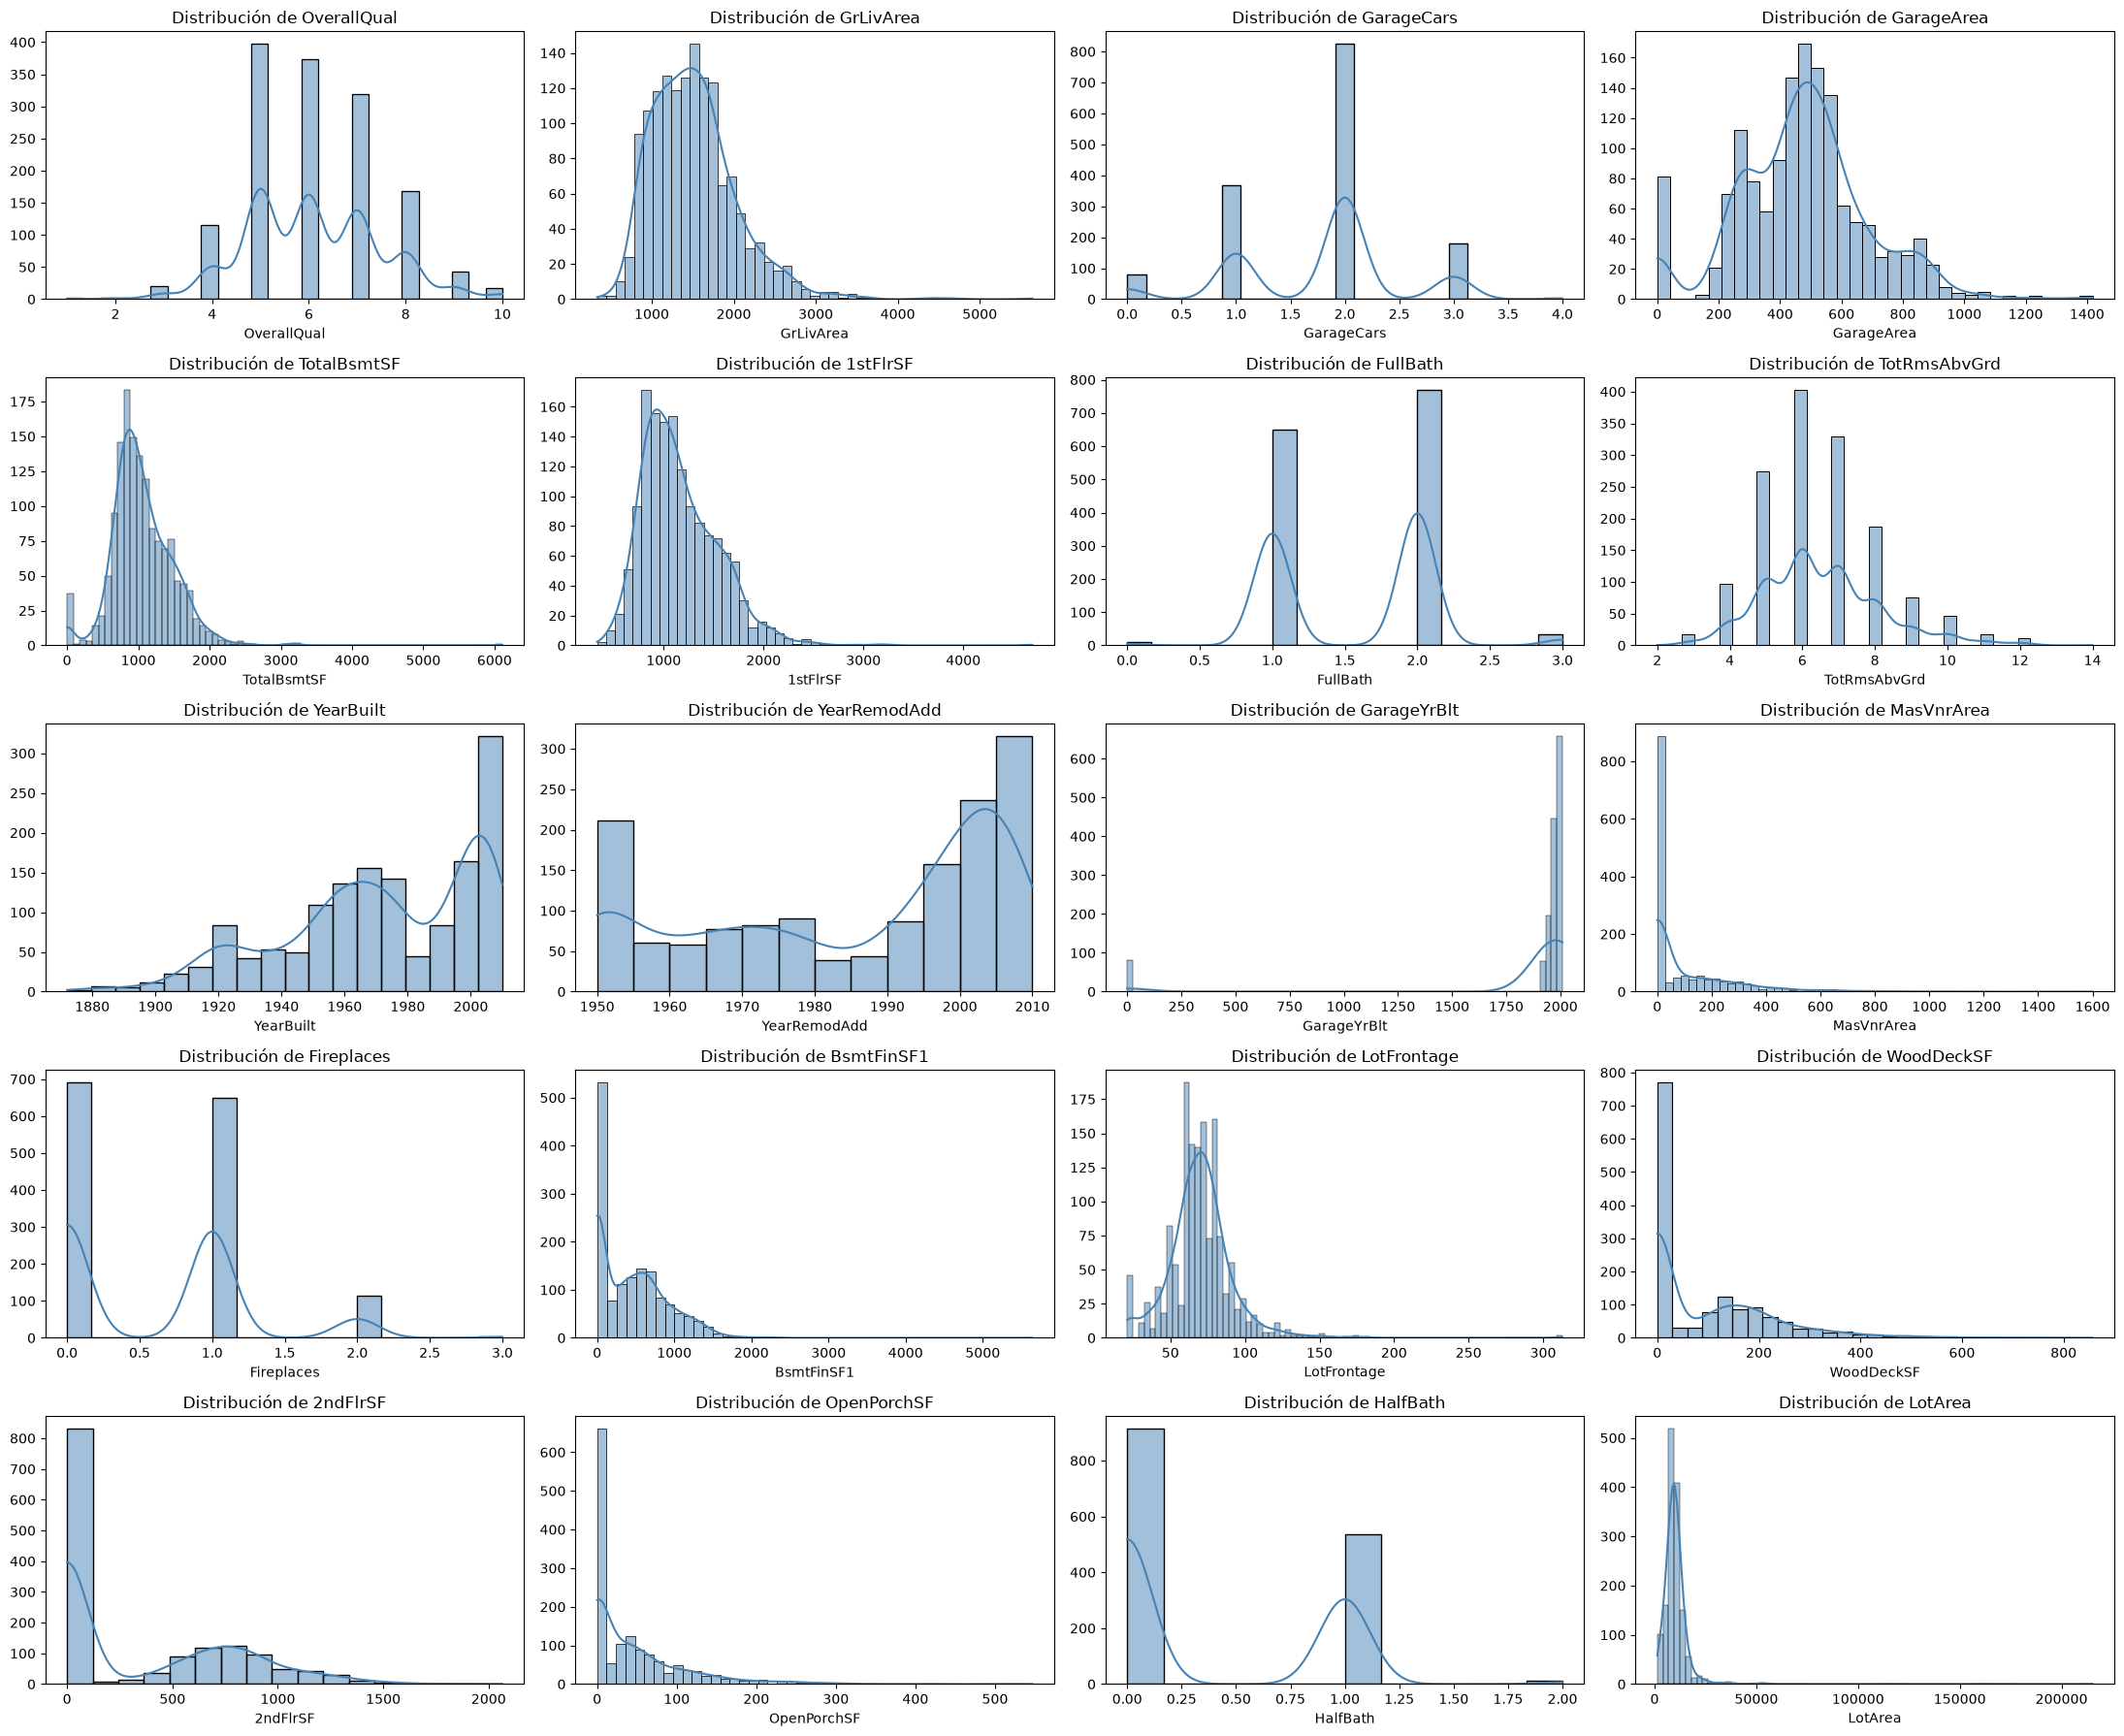

In [17]:
train_limpio = pd.read_csv('train_limpio.csv')

fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(22, 18))
axes = axes.flatten()

for i, col in enumerate(top_20_features):
    sns.histplot(train_limpio[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribución de {col}', fontsize=12)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

## ***Matriz de correlación***

In [18]:
matriz_corr = train_limpio[top_20_features].corr(method='pearson')

matriz_corr

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,GarageYrBlt,MasVnrArea,Fireplaces,BsmtFinSF1,LotFrontage,WoodDeckSF,2ndFlrSF,OpenPorchSF,HalfBath,LotArea
OverallQual,1.000000,0.593007,0.600671,0.562022,0.537808,0.476224,0.550600,0.427452,0.572323,0.550684,0.288998,0.407252,0.396765,0.239666,0.239546,0.238923,0.295493,0.308819,0.273458,0.105806
GrLivArea,0.593007,1.000000,0.467247,0.468997,0.454868,0.566024,0.630012,0.825489,0.199010,0.287389,0.162543,0.388052,0.461679,0.208171,0.385190,0.247433,0.687501,0.330224,0.415772,0.263116
GarageCars,0.600671,0.467247,1.000000,0.882475,0.434585,0.439317,0.469672,0.362289,0.537850,0.420622,0.598005,0.361945,0.300789,0.224054,0.281393,0.226342,0.183926,0.213569,0.219178,0.154871
GarageArea,0.562022,0.468997,0.882475,1.000000,0.486665,0.489782,0.405656,0.337822,0.478954,0.371600,0.560783,0.370884,0.269141,0.296970,0.339085,0.224666,0.138347,0.241435,0.163549,0.180403
TotalBsmtSF,0.537808,0.454868,0.434585,0.486665,1.000000,0.819530,0.323722,0.285573,0.391452,0.291066,0.176359,0.360067,0.339519,0.522396,0.381038,0.232019,-0.174512,0.247264,-0.048804,0.260833
1stFlrSF,0.476224,0.566024,0.439317,0.489782,0.819530,1.000000,0.380637,0.409516,0.281986,0.240379,0.166642,0.339850,0.410531,0.445863,0.434109,0.235459,-0.202646,0.211671,-0.119916,0.299475
FullBath,0.550600,0.630012,0.469672,0.405656,0.323722,0.380637,1.000000,0.554784,0.468271,0.439046,0.137464,0.272999,0.243671,0.058543,0.186561,0.187703,0.421378,0.259977,0.136381,0.126031
TotRmsAbvGrd,0.427452,0.825489,0.362289,0.337822,0.285573,0.409516,0.554784,1.000000,0.095589,0.191740,0.095607,0.279568,0.326114,0.044316,0.332619,0.165984,0.616423,0.234192,0.343415,0.190015
YearBuilt,0.572323,0.199010,0.537850,0.478954,0.391452,0.281986,0.468271,0.095589,1.000000,0.592855,0.272029,0.311600,0.147716,0.249503,0.120999,0.224880,0.010308,0.188686,0.242656,0.014228
YearRemodAdd,0.550684,0.287389,0.420622,0.371600,0.291066,0.240379,0.439046,0.191740,0.592855,1.000000,0.146357,0.176529,0.112581,0.128451,0.084550,0.205726,0.140024,0.226298,0.183331,0.013788


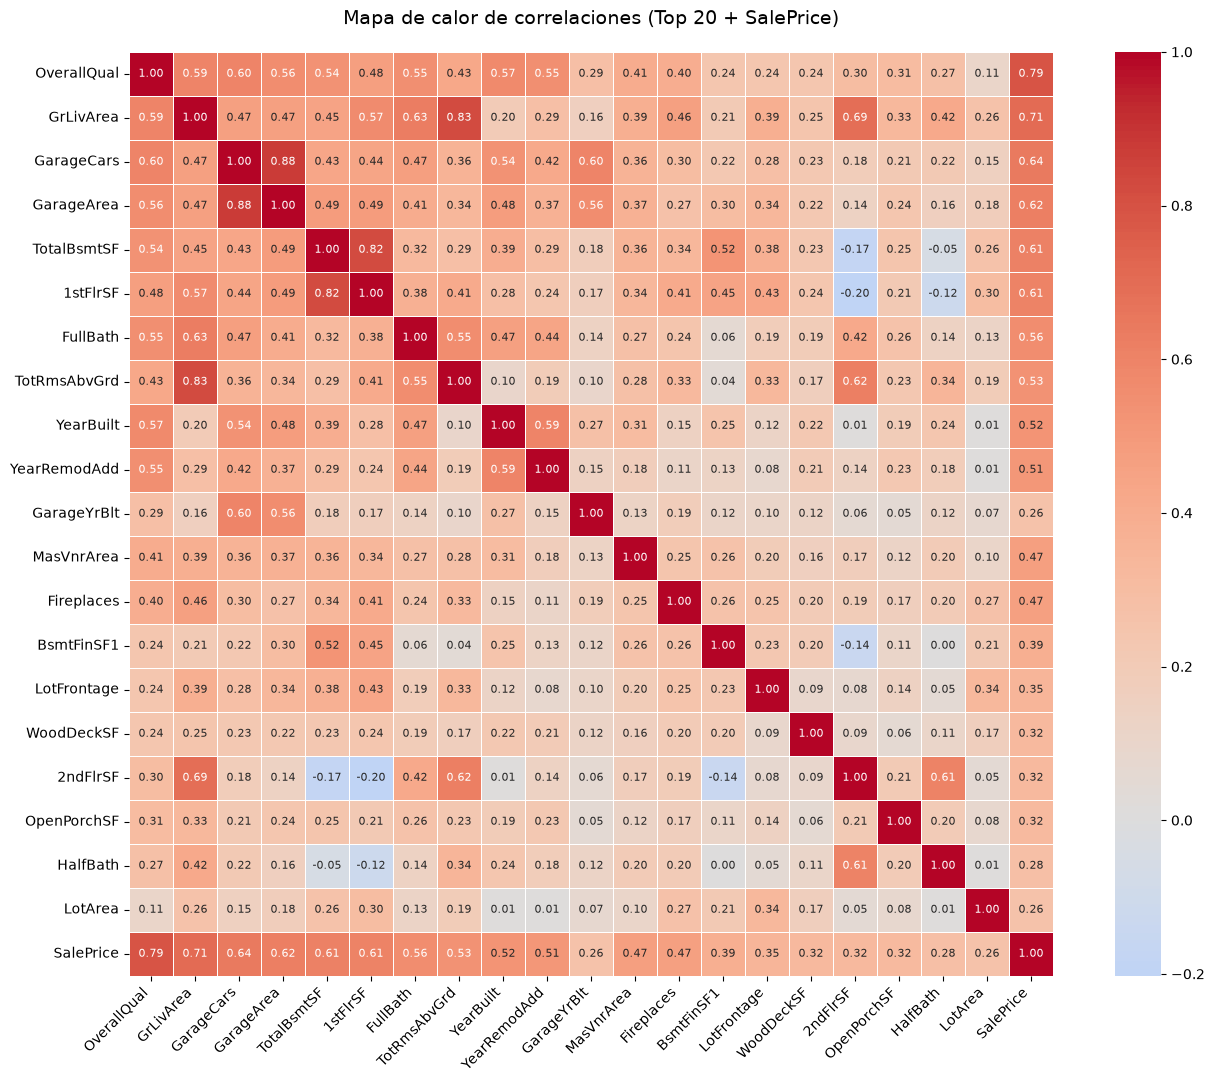

In [19]:
columnas_matriz = top_20_features + ['SalePrice']

matriz_corr = train_limpio[columnas_matriz].corr()

plt.figure(figsize=(16, 12)) # Tamaño ampliado para acomodar 21x21 celdas
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5, annot_kws={"size": 8})
plt.title('Mapa de calor de correlaciones (Top 20 + SalePrice)', pad=20, fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.show()

In [20]:
correlacion_con_precio = matriz_corr['SalePrice'].drop('SalePrice').sort_values(ascending=False)
correlacion_con_precio.to_frame(name='Correlación con SalePrice')

,Correlación con SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


## Relación de cada variable predictora con el precio

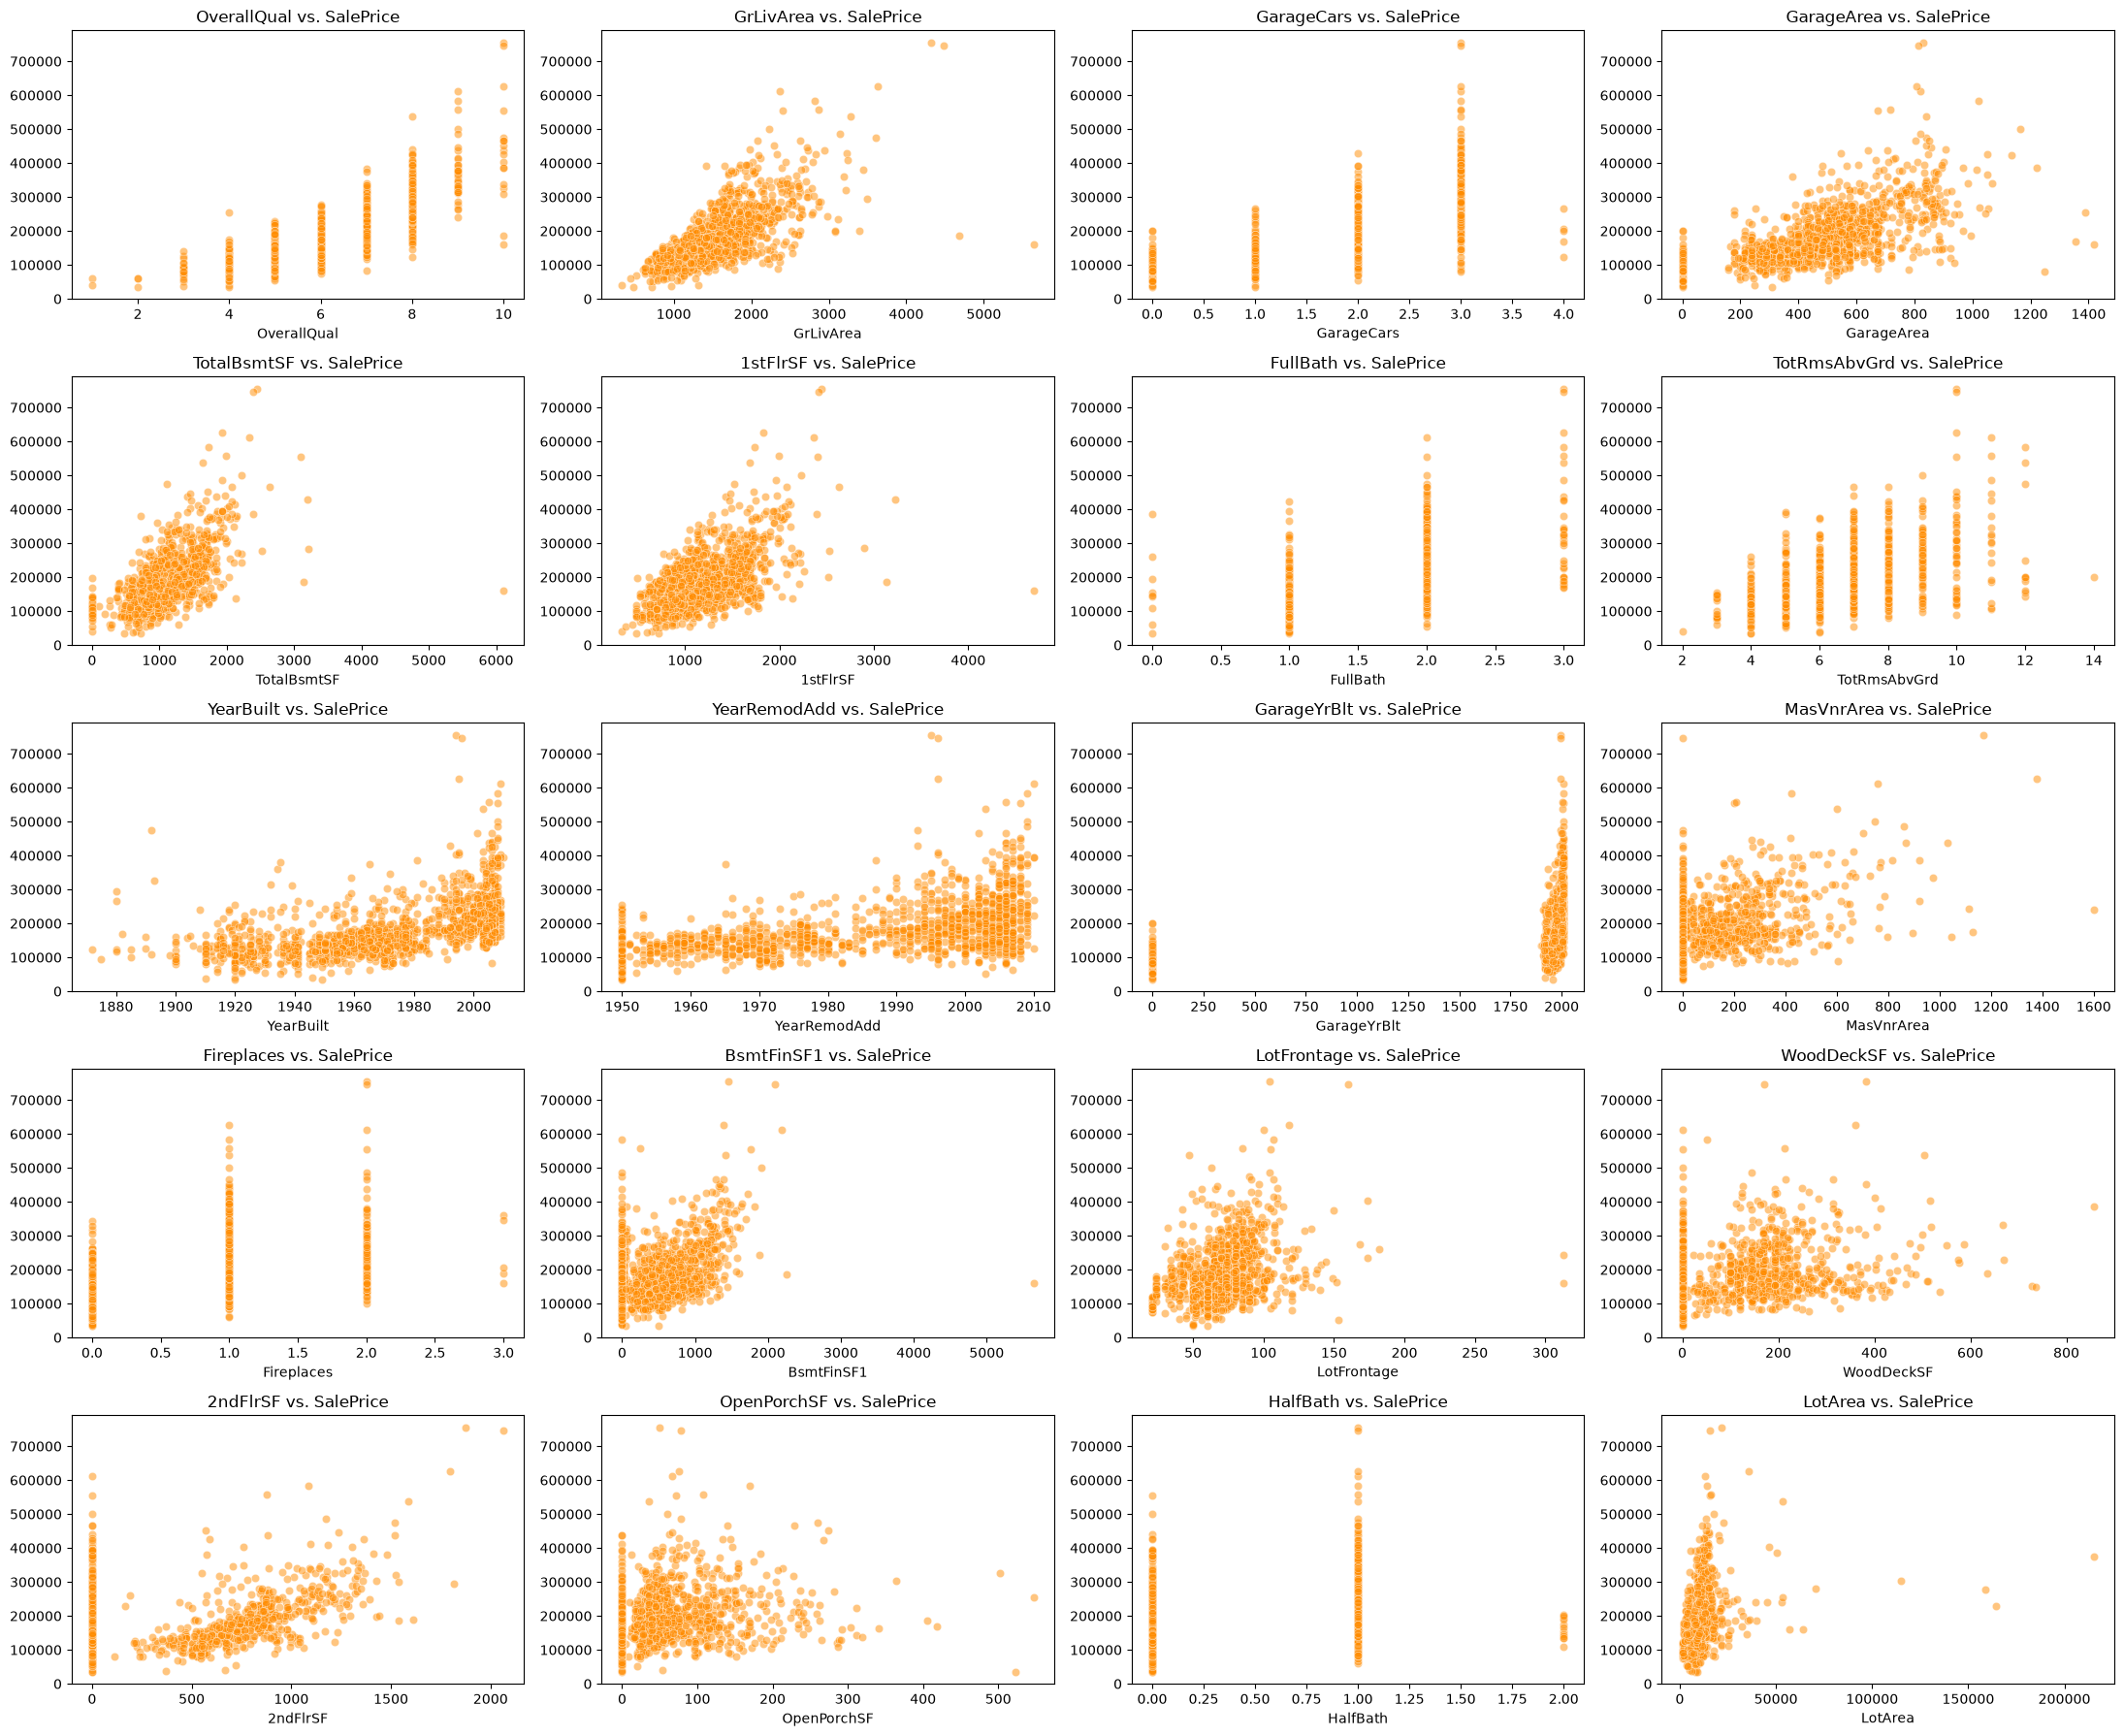

In [21]:
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(22, 18))
axes = axes.flatten()


for i, col in enumerate(top_20_features):
    sns.scatterplot(x=col, y='SalePrice', data=train_limpio, ax=axes[i], alpha=0.5, color='darkorange')
    axes[i].set_title(f'{col} vs. SalePrice', fontsize=12)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

## Detección de valores atípicos (outliers)

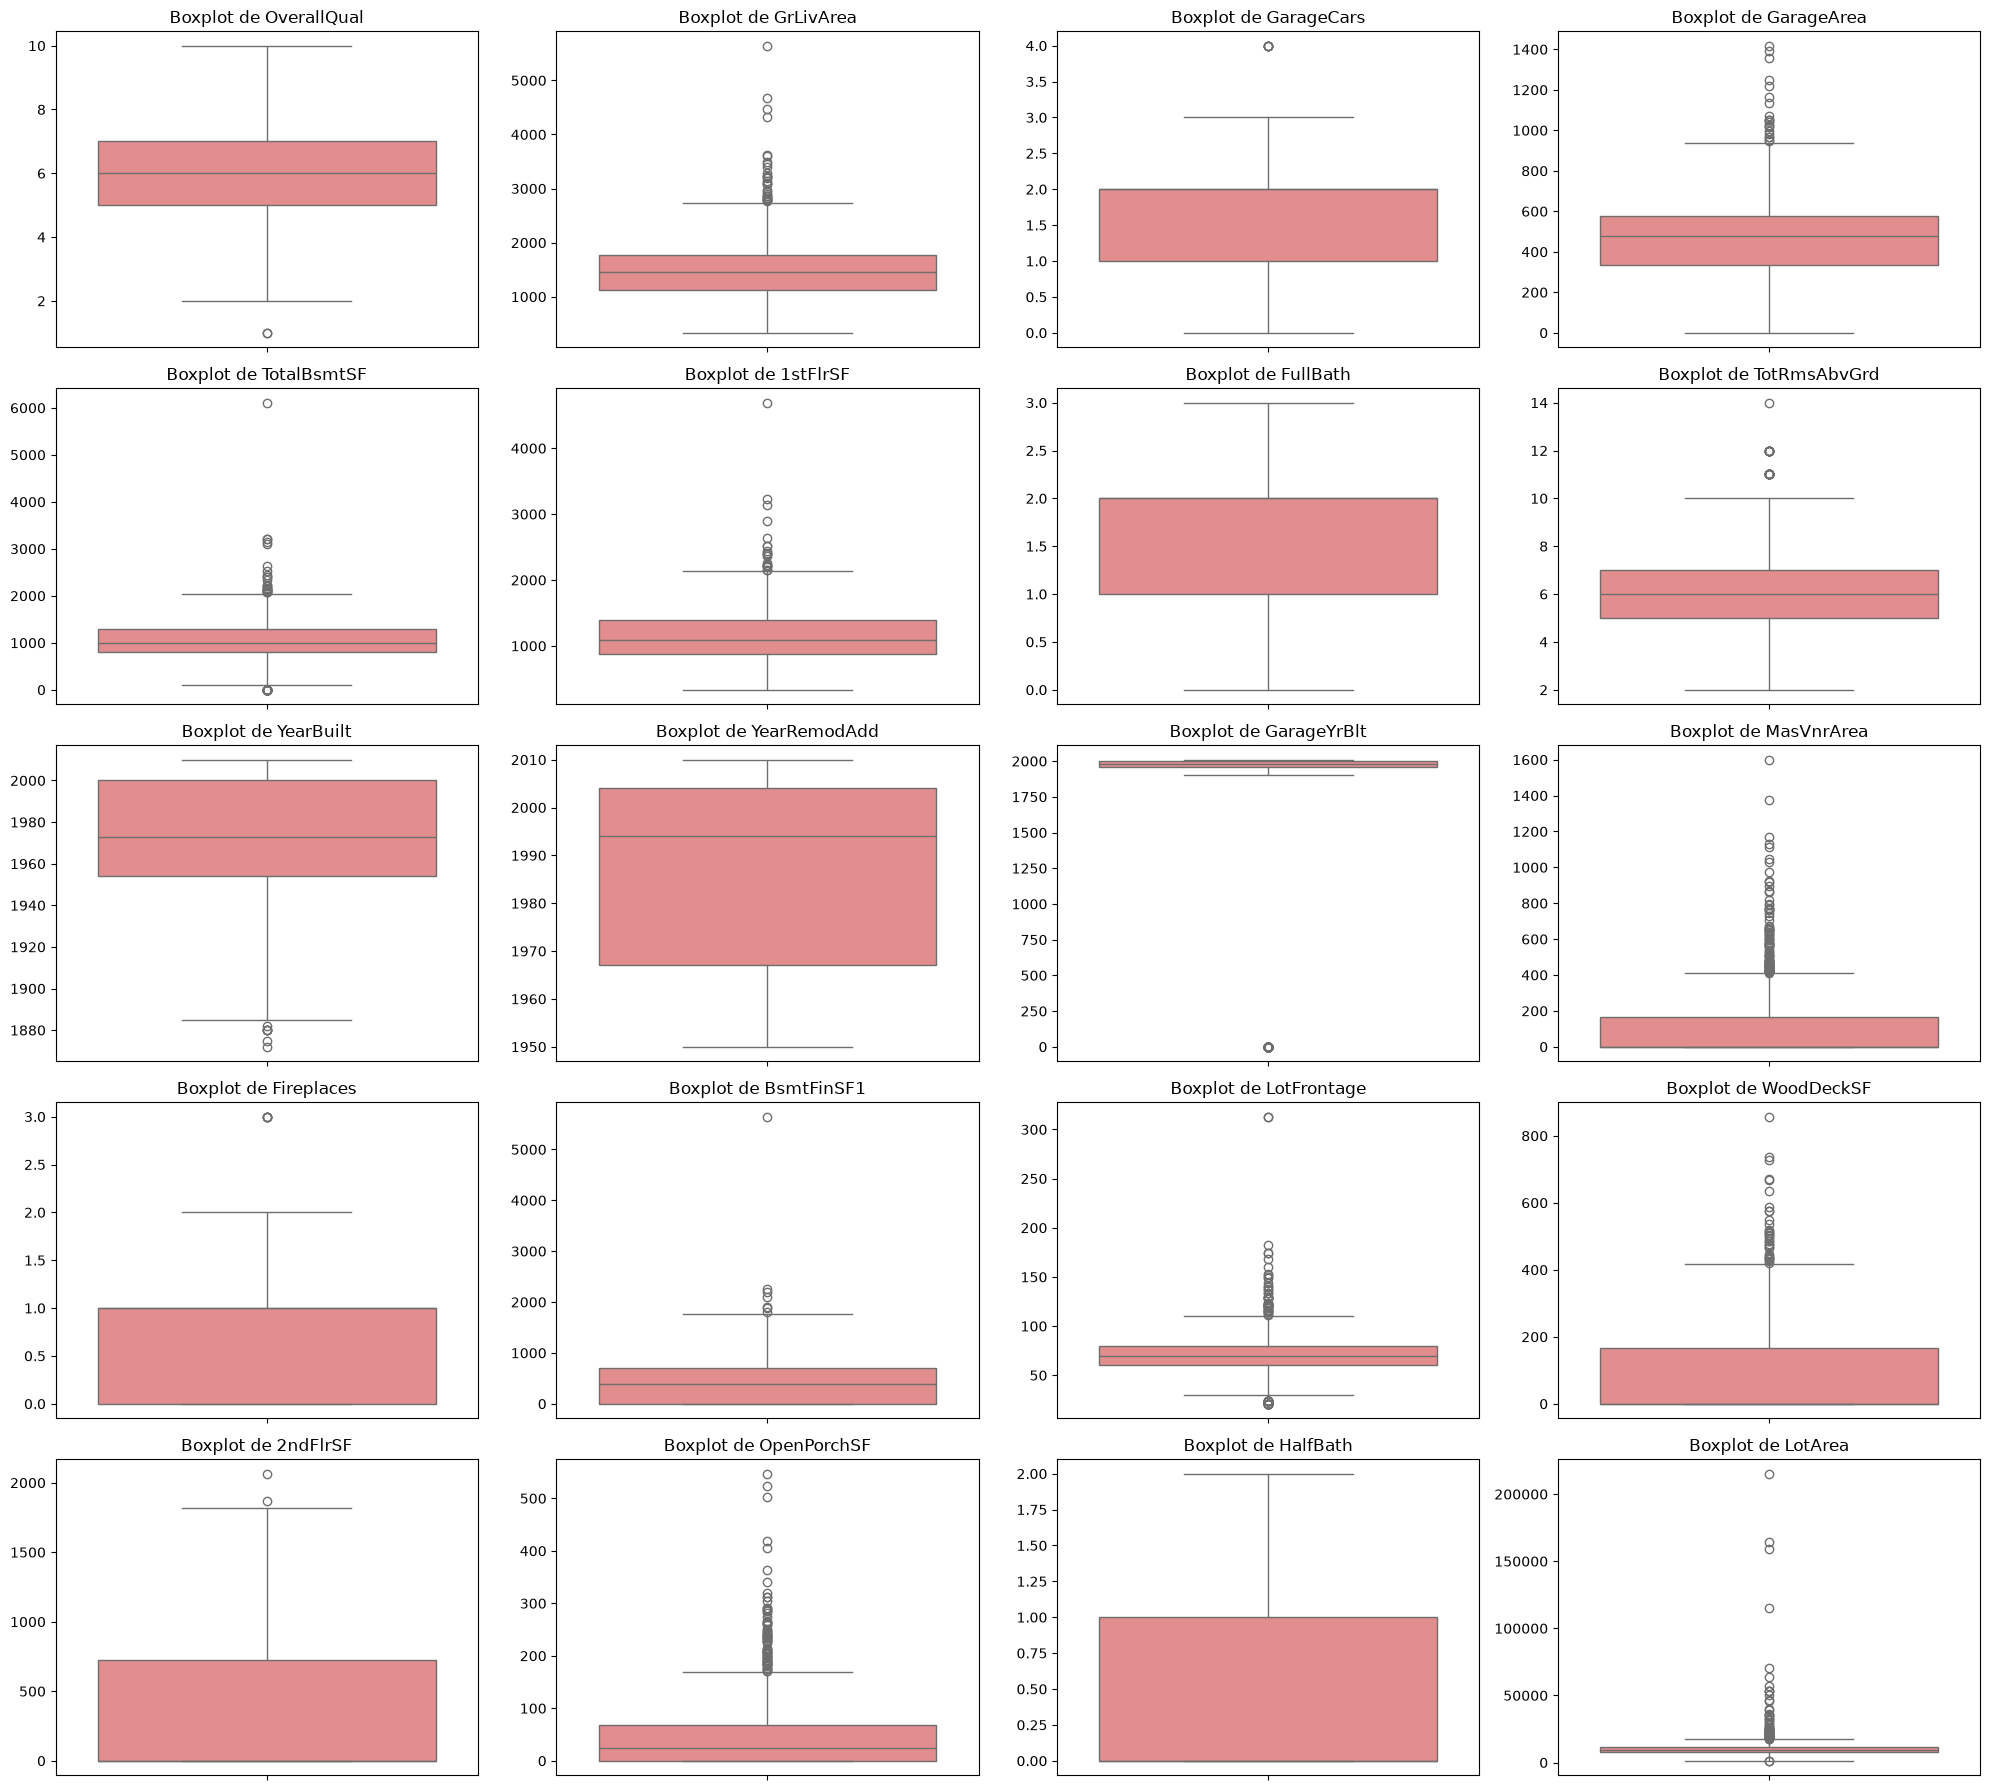

In [22]:
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 18))
axes = axes.flatten()

for i, col in enumerate(top_20_features):
    sns.boxplot(y=train_limpio[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Boxplot de {col}', fontsize=12)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 1. Cargar los datos limpios
train = pd.read_csv('train_limpio.csv')
test = pd.read_csv('test_limpio.csv')

# 2. Separar características (X) y variable objetivo (y)
X = train.drop(columns=['Id', 'SalePrice'])
y = train['SalePrice']
X_test = test.drop(columns=['Id'])
test_ids = test['Id']

# 3. Reservar el 20% de train.csv para validar los modelos
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Preparar el preprocesamiento para columnas numéricas y categóricas
columnas_numericas = X_train.select_dtypes(include=np.number).columns
columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns

preprocesador = ColumnTransformer(
    transformers=[
        ('numericas', make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler()
        ), columnas_numericas),
        ('categoricas', make_pipeline(
            SimpleImputer(strategy='constant', fill_value='Faltante'),
            OneHotEncoder(handle_unknown='ignore')
        ), columnas_categoricas)
    ]
)

# 5. Definir los modelos
modelos = {
    '01_RegresionLineal': LinearRegression(),
    '02_Ridge': Ridge(random_state=42),
    '03_Lasso': Lasso(random_state=42, max_iter=10000),
    '04_ElasticNet': ElasticNet(random_state=42, max_iter=10000),
    '05_RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    '06_GradientBoosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    '07_XGBoost': XGBRegressor(n_estimators=100, random_state=42),
    '08_LightGBM': LGBMRegressor(n_estimators=100, random_state=42),
    '09_SVR': SVR(kernel='linear'),
    '10_KNN': KNeighborsRegressor(n_neighbors=5)
}

# 6. Evaluar cada modelo y luego entrenarlo con todos los datos para generar su entrega
for nombre, modelo in modelos.items():
    print(f'\nEvaluando modelo: {nombre}...')
    pipeline = make_pipeline(preprocesador, modelo)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)

    mape = np.mean(np.abs((y_val - y_pred) / y_val)) * 100
    bias = np.mean(y_pred - y_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    print(f'MAPE: {mape:.2f}%')
    print(f'Bias: {bias:.2f}')
    print(f'RMSE: {rmse:.2f}')
    print(f'R2: {r2:.4f}')

    # Reentrenar con todo train.csv y predecir test.csv
    pipeline.fit(X, y)
    predicciones = pipeline.predict(X_test)
    entrega = pd.DataFrame({'Id': test_ids, 'SalePrice': predicciones})
    entrega.to_csv(f'submission_{nombre}.csv', index=False)

print('\n¡La evaluación y las 10 entregas se completaron!')



Evaluando modelo: 01_RegresionLineal...
MAPE: 12.86%
Bias: -4274.48
RMSE: 65296.42
R2: 0.4441

Evaluando modelo: 02_Ridge...
MAPE: 11.56%
Bias: -1701.62
RMSE: 29758.54
R2: 0.8845

Evaluando modelo: 03_Lasso...


/Users/Apple/Library/Python/3.14/lib/python/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.164881e+10, tolerance: 6.967e+08
  model = cd_fast.sparse_enet_coordinate_descent(


MAPE: 11.97%
Bias: -2915.10
RMSE: 42336.12
R2: 0.7663

Evaluando modelo: 04_ElasticNet...
MAPE: 11.28%
Bias: -2842.40
RMSE: 36128.96
R2: 0.8298

Evaluando modelo: 05_RandomForest...
MAPE: 10.66%
Bias: -1342.38
RMSE: 29095.29
R2: 0.8896

Evaluando modelo: 06_GradientBoosting...
MAPE: 10.10%
Bias: -632.95
RMSE: 27638.09
R2: 0.9004

Evaluando modelo: 07_XGBoost...
MAPE: 10.25%
Bias: -1313.74
RMSE: 28752.07
R2: 0.8922

Evaluando modelo: 08_LightGBM...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003268 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3238
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 193
[LightGBM] [Info] Start training from score 181441.541952
MAPE: 10.21%
Bias: -1323.02
RMSE: 29505.50
R2: 0.8865
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing w